In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from mpl_toolkits.mplot3d import Axes3D
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']  # 设置中文字体
plt.rcParams['axes.unicode_minus'] = False  # 解决负号显示问题


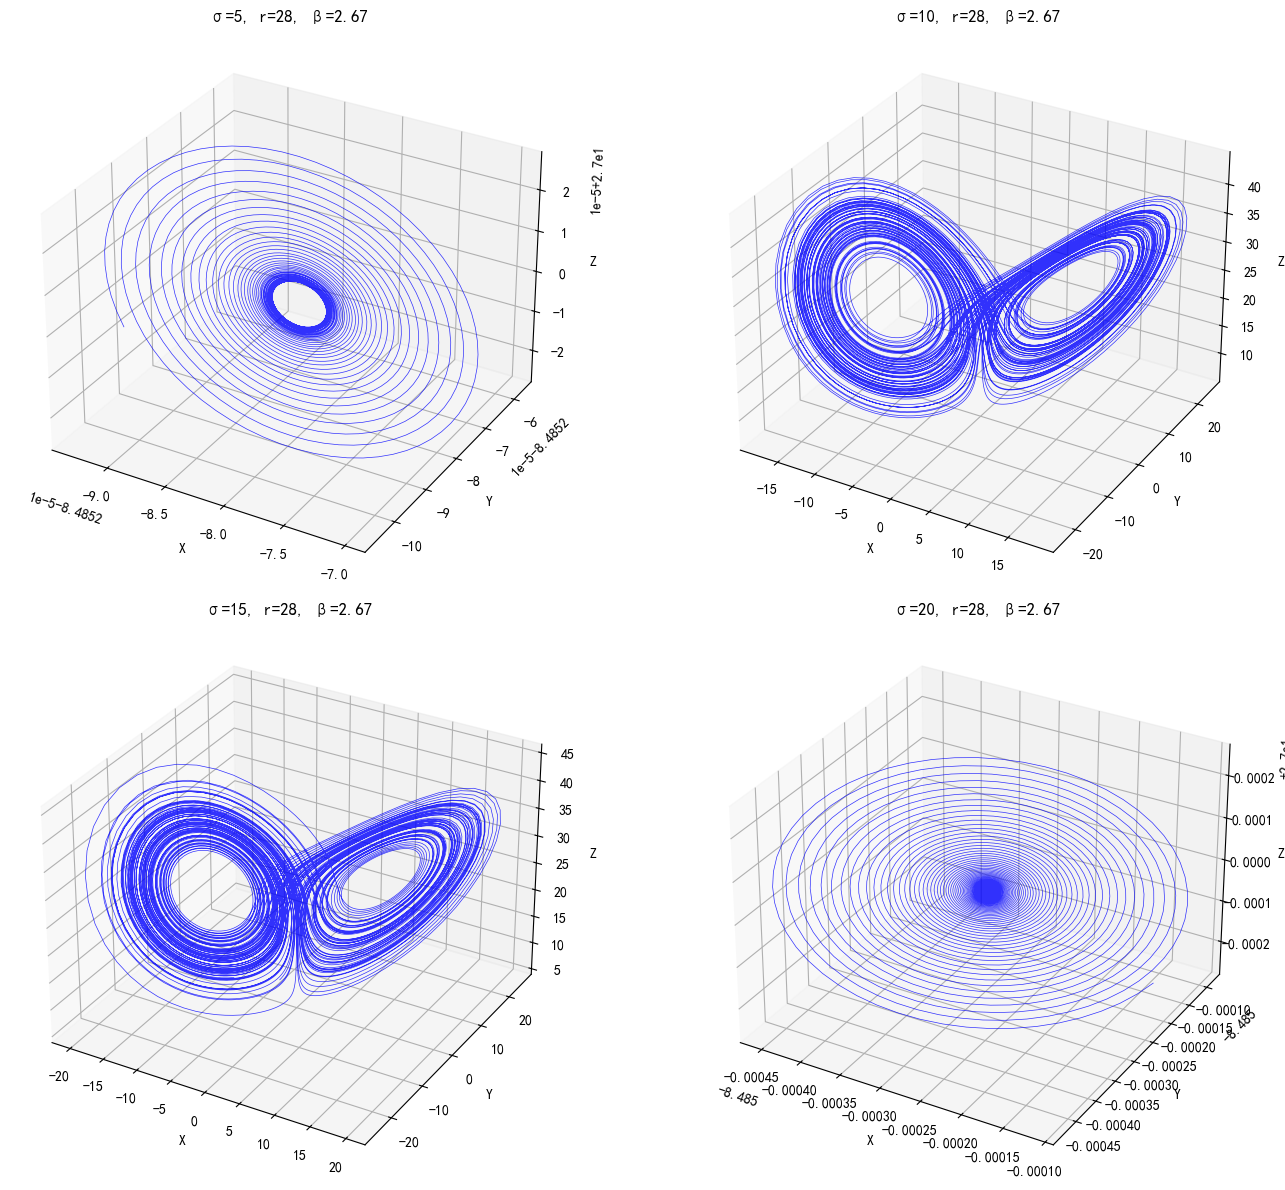

In [7]:

def lorenz_system(t, state, sigma, r, beta):
    x, y, z = state
    dxdt = sigma * (y - x)
    dydt = x * (r - z) - y
    dzdt = x * y - beta * z
    return [dxdt, dydt, dzdt]

def simulate_lorenz(sigma=10, r=28, beta=8/3, 
                    initial_state=[1, 1, 1], 
                    T=200, dt=0.01):
    t_eval = np.arange(0, T, dt)
    sol = solve_ivp(lorenz_system, [0, T], initial_state, 
                    t_eval=t_eval, args=(sigma, r, beta), 
                    method='RK45', rtol=1e-8, atol=1e-10)
    
    # 舍弃暂态过程
    transient = int(len(t_eval) * 0.5)
    x, y, z = sol.y[0][transient:], sol.y[1][transient:], sol.y[2][transient:]
    t = t_eval[transient:]
    
    return t, x, y, z

def plot_sigma_variation():
    sigma_values = [5, 10, 15, 20]
    r, beta = 28, 8/3
    
    fig = plt.figure(figsize=(15, 12))
    
    for i, sigma in enumerate(sigma_values, 1):
        t, x, y, z = simulate_lorenz(sigma=sigma, r=r, beta=beta, T=200, dt=0.01)
        
        # 3D相图
        ax = fig.add_subplot(2, 2, i, projection='3d')
        ax.plot(x, y, z, lw=0.5, alpha=0.8, color='b')
        ax.set_title(f'σ={sigma}, r={r}, β={beta:.2f}', fontsize=12)
        ax.set_xlabel('X', fontsize=10)
        ax.set_ylabel('Y', fontsize=10)
        ax.set_zlabel('Z', fontsize=10)
        ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('sigma_variation.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    return sigma_values

if __name__ == '__main__':
    sigma_vals = plot_sigma_variation()

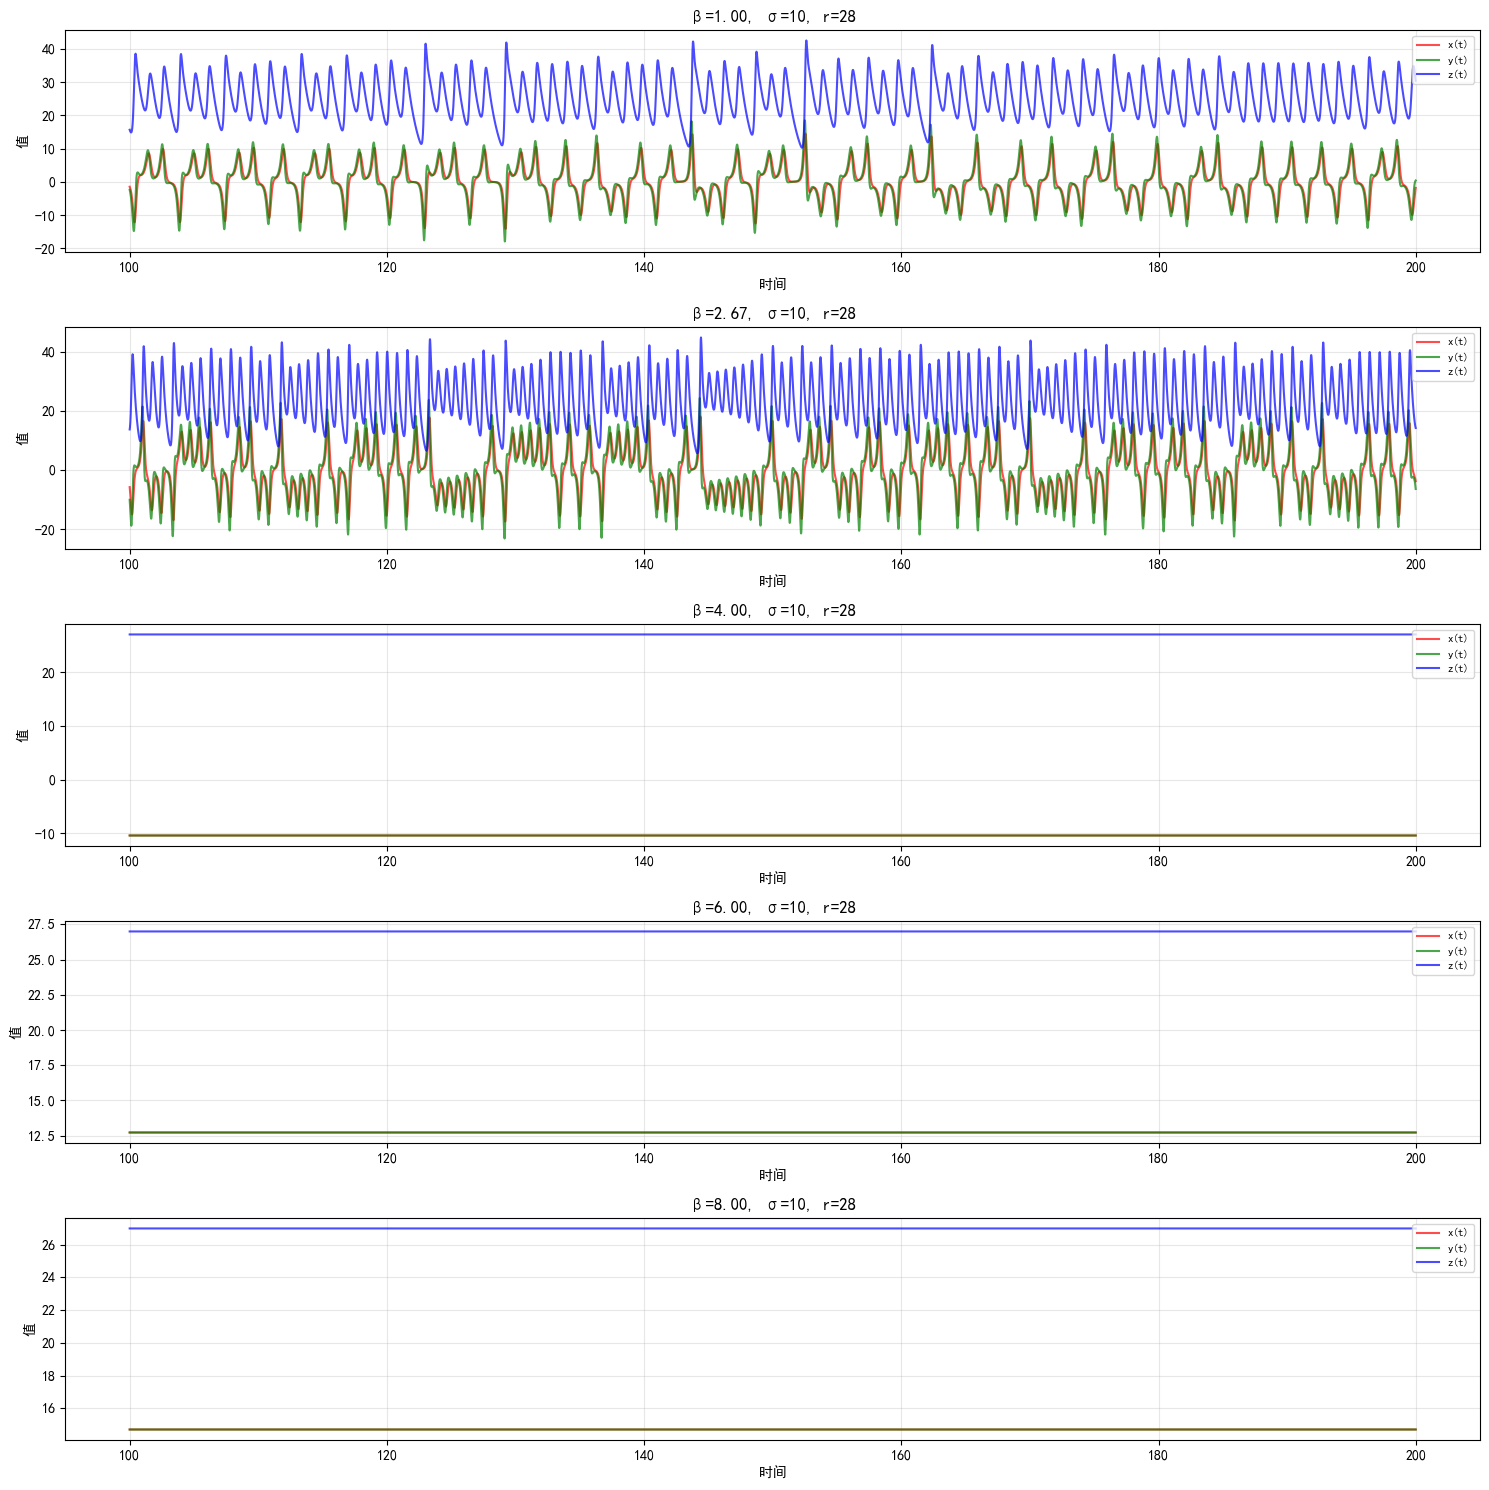

In [6]:
def plot_beta_variation():
    beta_values = [1, 8/3, 4, 6, 8]
    sigma, r = 10, 28
    
    fig = plt.figure(figsize=(15, 15))
    
    for i, beta in enumerate(beta_values, 1):
        t, x, y, z = simulate_lorenz(sigma=sigma, r=r, beta=beta, T=200, dt=0.01)
        
        # 时间序列
        ax = fig.add_subplot(len(beta_values), 1, i)
        line1, = ax.plot(t, x, label='x(t)', alpha=0.7, color='r')
        line2, = ax.plot(t, y, label='y(t)', alpha=0.7, color='g')
        line3, = ax.plot(t, z, label='z(t)', alpha=0.7, color='b')
        ax.set_title(f'β={beta:.2f}, σ={sigma}, r={r}', fontsize=12)
        ax.set_xlabel('时间', fontsize=10)
        ax.set_ylabel('值', fontsize=10)
        ax.legend(loc='upper right', fontsize=8)
        ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('beta_variation.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    return beta_values

if __name__ == '__main__':
    beta_vals = plot_beta_variation()

开始参数空间扫描...
r=0.0, β=1.00, λ=-9.4896
r=0.0, β=2.00, λ=-9.3578
r=0.0, β=3.00, λ=-8.5764
r=0.0, β=4.00, λ=-9.1733
r=0.0, β=5.00, λ=-6.9168
r=0.0, β=6.00, λ=-7.4666
r=0.0, β=7.00, λ=-7.2633
r=0.0, β=8.00, λ=-5.8063
r=0.0, β=9.00, λ=-7.1948
r=0.0, β=10.00, λ=-10.0352
r=5.6, β=1.00, λ=-6.3142
r=5.6, β=2.00, λ=-5.7901
r=5.6, β=3.00, λ=-2.4399
r=5.6, β=4.00, λ=-1.0271
r=5.6, β=5.00, λ=-2.1413
r=5.6, β=6.00, λ=-1.2989
r=5.6, β=7.00, λ=-1.2912
r=5.6, β=8.00, λ=-1.5074
r=5.6, β=9.00, λ=-2.4743
r=5.6, β=10.00, λ=-2.9774
r=11.1, β=1.00, λ=-4.1322
r=11.1, β=2.00, λ=-1.5103
r=11.1, β=3.00, λ=-3.9675
r=11.1, β=4.00, λ=-1.7344
r=11.1, β=5.00, λ=-1.4121
r=11.1, β=6.00, λ=-1.5883
r=11.1, β=7.00, λ=-0.6339
r=11.1, β=8.00, λ=-0.3638
r=11.1, β=9.00, λ=-0.4533
r=11.1, β=10.00, λ=-0.1263
r=16.7, β=1.00, λ=9.0151
r=16.7, β=2.00, λ=-2.3891
r=16.7, β=3.00, λ=-0.6823
r=16.7, β=4.00, λ=-6.4954
r=16.7, β=5.00, λ=-2.0027
r=16.7, β=6.00, λ=-5.6119
r=16.7, β=7.00, λ=-0.5116
r=16.7, β=8.00, λ=-1.2545
r=16.7, β=9.00, λ

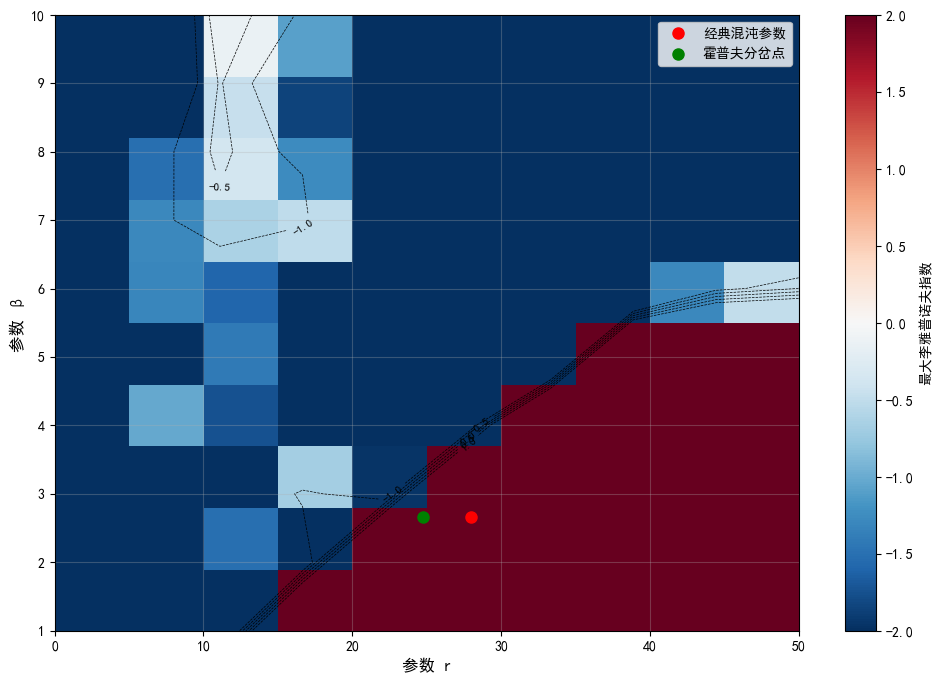

In [10]:
def calculate_lyapunov_exponent(sigma, r, beta, initial_state=[1, 1, 1], 
                               T=1000, dt=0.01, d0=1e-7):
    """计算最大李雅普诺夫指数"""
    t_eval = np.arange(0, T, dt)
    
    # 参考轨迹
    sol1 = solve_ivp(lorenz_system, [0, T], initial_state, 
                     t_eval=t_eval, args=(sigma, r, beta), 
                     method='RK45', rtol=1e-8, atol=1e-10)
    
    # 扰动轨迹
    perturbed_state = [initial_state[0] + d0, 
                      initial_state[1], 
                      initial_state[2]]
    sol2 = solve_ivp(lorenz_system, [0, T], perturbed_state, 
                     t_eval=t_eval, args=(sigma, r, beta), 
                     method='RK45', rtol=1e-8, atol=1e-10)
    
    # 舍弃暂态
    transient = int(len(t_eval) * 0.3)
    
    # 计算李雅普诺夫指数
    lsum = 0
    count = 0
    
    for i in range(transient, len(t_eval)-100, 100):  # 每隔100步采样一次
        # 计算距离
        d1 = np.sqrt(
            (sol1.y[0,i] - sol2.y[0,i])**2 +
            (sol1.y[1,i] - sol2.y[1,i])**2 +
            (sol1.y[2,i] - sol2.y[2,i])**2
        )
        
        if d1 > 0:
            lsum += np.log(d1/d0)
            count += 1
    
    if count > 0:
        return lsum / (count * 100 * dt)  # 修正时间间隔
    else:
        return 0

def parameter_space_scan():
    """参数空间扫描"""
    sigma = 10
    r_values = np.linspace(0, 50, 10)
    beta_values = np.linspace(1, 10, 10)
    
    # 存储李雅普诺夫指数
    lyap_matrix = np.zeros((len(r_values), len(beta_values)))
    
    print("开始参数空间扫描...")
    for i, r in enumerate(r_values):
        for j, beta in enumerate(beta_values):
            # 计算最大李雅普诺夫指数
            lyap = calculate_lyapunov_exponent(sigma, r, beta, T=500, dt=0.02)
            lyap_matrix[i, j] = lyap
            print(f"r={r:.1f}, β={beta:.2f}, λ={lyap:.4f}")
    
    # 绘制热图
    plt.figure(figsize=(12, 8))
    im = plt.imshow(lyap_matrix.T, extent=[0, 50, 1, 10], 
                    origin='lower', aspect='auto', cmap='RdBu_r', vmin=-2, vmax=2)
    plt.colorbar(im, label='最大李雅普诺夫指数')
    plt.xlabel('参数 r', fontsize=12)
    plt.ylabel('参数 β', fontsize=12)
    # 添加等值线
    CS = plt.contour(r_values, beta_values, lyap_matrix.T, 
                     levels=[-1, -0.5, 0, 0.5, 1], colors='k', linestyles='--', linewidths=0.5)
    plt.clabel(CS, inline=True, fontsize=8)
    
    # 标记经典参数点
    plt.plot(28, 8/3, 'ro', markersize=8, label='经典混沌参数')
    plt.plot(24.74, 8/3, 'go', markersize=8, label='霍普夫分岔点')
    
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.savefig('parameter_space_scan.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    return r_values, beta_values, lyap_matrix

if __name__ == '__main__':
    r_vals, beta_vals, lyap_mat = parameter_space_scan()

开始生成分岔图...
进度: 0.0%
进度: 9.8%
进度: 19.6%
进度: 29.4%
进度: 39.2%
进度: 49.0%
进度: 58.8%
进度: 68.6%
进度: 78.4%
进度: 88.2%
进度: 98.0%


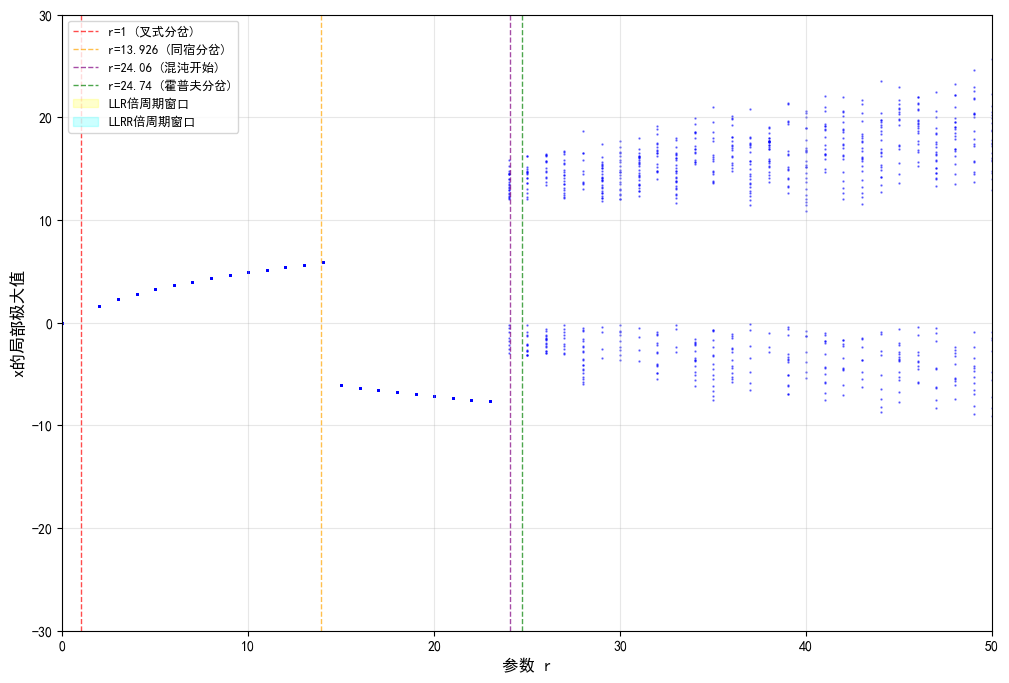

In [12]:
def bifurcation_diagram():
    """生成分岔图"""
    sigma, beta = 10, 8/3
    r_values = np.linspace(0, 50, 51)  # 增加采样密度
    
    # 存储局部极大值
    bifurcation_data = []
    
    print("开始生成分岔图...")
    for idx, r in enumerate(r_values):
        # 模拟系统，使用较长的模拟时间以确保系统进入渐近状态
        t, x, y, z = simulate_lorenz(sigma=sigma, r=r, beta=beta, 
                                     T=500, dt=0.01)
        
        # 找到x的局部极大值
        x_array = np.array(x)
        local_maxima = []
        
        # 使用更精确的局部极大值检测
        for i in range(2, len(x_array)-2):
            if (x_array[i] > x_array[i-1] and 
                x_array[i] > x_array[i-2] and
                x_array[i] > x_array[i+1] and
                x_array[i] > x_array[i+2]):
                local_maxima.append(x_array[i])
        
        # 取后30个局部极大值（如果存在）
        if len(local_maxima) > 30:
            for val in local_maxima[-30:]:
                bifurcation_data.append((r, val))
        
        if idx % 5 == 0:
            print(f"进度: {idx/len(r_values)*100:.1f}%")
    
    # 绘制分岔图
    plt.figure(figsize=(12, 8))
    
    if bifurcation_data:
        r_vals, x_vals = zip(*bifurcation_data)
        plt.scatter(r_vals, x_vals, s=0.5, alpha=0.5, c='blue')
    
    plt.xlabel('参数 r', fontsize=12)
    plt.ylabel('x的局部极大值', fontsize=12)
    plt.grid(True, alpha=0.3)
    
    # 标记关键区域
    plt.axvline(x=1, color='red', linestyle='--', alpha=0.7, linewidth=1, label='r=1 (叉式分岔)')
    plt.axvline(x=13.926, color='orange', linestyle='--', alpha=0.7, linewidth=1, label='r=13.926 (同宿分岔)')
    plt.axvline(x=24.06, color='purple', linestyle='--', alpha=0.7, linewidth=1, label='r=24.06 (混沌开始)')
    plt.axvline(x=24.74, color='green', linestyle='--', alpha=0.7, linewidth=1, label='r=24.74 (霍普夫分岔)')
    
    # 标记倍周期分岔窗口
    plt.axvspan(99.5, 100.8, alpha=0.2, color='yellow', label='LLR倍周期窗口')
    plt.axvspan(145, 166, alpha=0.2, color='cyan', label='LLRR倍周期窗口')
    
    plt.legend(loc='upper left', fontsize=9)
    plt.xlim(0, 50)
    plt.ylim(-30, 30)
    
    plt.savefig('bifurcation_diagram.png', dpi=300, bbox_inches='tight')
    plt.show()

if __name__ == '__main__':
    bifurcation_diagram()

In [ ]:
def lyapunov_spectrum_analysis():
    """计算李雅普诺夫指数谱"""
    sigma, beta = 10, 8/3
    r_values = np.linspace(0, 100, 20)
    
    # 存储三个李雅普诺夫指数
    lyap1_values = []
    lyap2_values = []
    lyap3_values = []
    
    print("开始计算李雅普诺夫指数谱...")
    for idx, r in enumerate(r_values):
        # 简化计算：只计算最大李雅普诺夫指数，其他两个通过约束关系估算
        lambda1 = calculate_lyapunov_exponent(sigma, r, beta, T=800, dt=0.02)
        
        # 根据约束条件估算另外两个指数
        # λ1 + λ2 + λ3 = -σ - 1 - β = -13.67
        # 对于混沌吸引子，λ2 ≈ 0，λ3 ≈ -13.67 - λ1
        # 对于稳定不动点，λ1, λ2, λ3均为负值
        # 对于极限环，λ1 ≈ 0，λ2, λ3为负值
        
        if lambda1 > 0.05:  # 混沌状态
            lambda2 = 0.0
            lambda3 = -13.67 - lambda1
        elif lambda1 > -0.05:  # 接近周期状态
            lambda2 = -5.0  # 估计值
            lambda3 = -13.67 - lambda1 - lambda2
        else:  # 稳定状态
            lambda2 = -2.0  # 估计值
            lambda3 = -13.67 - lambda1 - lambda2
        
        lyap1_values.append(lambda1)
        lyap2_values.append(lambda2)
        lyap3_values.append(lambda3)
        
        if idx % 1 == 0:
            print(f"r={r:.1f}, λ1={lambda1:.3f}, λ2={lambda2:.3f}, λ3={lambda3:.3f}")
    
    # 绘制李雅普诺夫指数谱
    plt.figure(figsize=(12, 8))
    
    plt.plot(r_values, lyap1_values, 'b-', linewidth=2, label='λ₁ (最大指数)')
    plt.plot(r_values, lyap2_values, 'g-', linewidth=2, label='λ₂')
    plt.plot(r_values, lyap3_values, 'r-', linewidth=2, label='λ₃')
    plt.axhline(y=0, color='k', linestyle='--', alpha=0.5, linewidth=1)
    
    # 填充不同动力学区域
    plt.axvspan(0, 1, alpha=0.1, color='green', label='稳定不动点')
    plt.axvspan(1, 24.06, alpha=0.1, color='yellow', label='暂态混沌')
    plt.axvspan(24.06, 100, alpha=0.1, color='red', label='混沌区域')
    
    plt.xlabel('参数 r', fontsize=12)
    plt.ylabel('李雅普诺夫指数', fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.legend(loc='upper left', fontsize=10)
    plt.xlim(0, 100)
    plt.ylim(-20, 5)
    
    plt.savefig('lyapunov_spectrum.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    return r_values, lyap1_values, lyap2_values, lyap3_values

if __name__ == '__main__':
    r_vals, lyap1, lyap2, lyap3 = lyapunov_spectrum_analysis()

开始计算李雅普诺夫指数谱...
r=0.0, λ1=-8.650, λ2=-2.000, λ3=-3.020
r=5.3, λ1=-4.681, λ2=-2.000, λ3=-6.989
r=10.5, λ1=-3.074, λ2=-2.000, λ3=-8.596
r=15.8, λ1=-2.057, λ2=-2.000, λ3=-9.613
r=21.1, λ1=-0.808, λ2=-2.000, λ3=-10.862
r=26.3, λ1=9.409, λ2=0.000, λ3=-23.079
r=31.6, λ1=9.491, λ2=0.000, λ3=-23.161
r=36.8, λ1=9.551, λ2=0.000, λ3=-23.221
r=42.1, λ1=9.540, λ2=0.000, λ3=-23.210
r=47.4, λ1=9.580, λ2=0.000, λ3=-23.250
r=52.6, λ1=9.630, λ2=0.000, λ3=-23.300
